# Eye 모델 보강 실험

EPA eye 엔드포인트(673행 · 특성 2,265개)에서 모델을 보강할 방법을 찾기 위한 실험 묶음입니다.

**이 노트북이 하지 않는 것** — 기존 production 실행을 다시 돌리거나 덮어쓰지 않습니다.
무거운 계산은 전부 `run_experiments.py`가 수행해 `results/`에 캐시해 두었고,
여기서는 그 결과를 불러와 분석만 합니다.

## 프로토콜과 한계

| 항목 | 내용 |
|---|---|
| 교차검증 | 외부 5-fold × 내부 3-fold grouped nested CV (production과 동일 코드) |
| 임계값 | 내부 OOF에서 민감도–특이도 차 최소화 → MCC 최대화 → 작은 값 (외부 정답 미사용) |
| 표본 가중 | balanced sample weight |
| **후보 격자** | **20개 중 6개로 축소** — 계산량 때문. LR은 발표값과 정확히 일치하지만 SVM 등 일부는 다릅니다 |
| 유효한 비교 | **같은 프로토콜 안에서 짝지은 차이**만 의미가 있습니다. 발표된 절대 수치와 직접 비교하지 마십시오 |
| 반복 | seed 42 / 202 / 777 |

> 격자를 줄였기 때문에 이 노트북의 절대 수치는 `label 조합 변경/EPA` 의 발표 결과와 다를 수 있습니다.
> 모든 결론은 **같은 조건에서 A와 B를 나란히 돌린 차이**에 근거합니다.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties, fontManager

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import experiment_utils as X

FONT = Path("C:/Windows/Fonts/malgun.ttf")
fontManager.addfont(str(FONT))
plt.rcParams.update({
    "font.family": FontProperties(fname=FONT).get_name(),
    "axes.unicode_minus": False,
    "figure.dpi": 110,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

def load(name):
    return json.loads((X.RESULTS / f"{name}.json").read_text(encoding="utf-8"))

def frame(name):
    return pd.DataFrame(load(name))

df, M, cols = X.load_eye()
print("eye", M.shape, "| 등급 분포", df.final_label.value_counts().sort_index().to_dict())

eye (673, 2265) | 등급 분포 {1: 65, 2: 60, 3: 300, 4: 248}


---
## 00. 데이터 진단

실험을 설계하기 전에 데이터가 어떤 상태인지부터 확인합니다.
여기서 나오는 두 가지가 이후 모든 실험의 전제를 바꿉니다.

In [2]:
diag = load("00_diagnostics")
print(f"행 수                     {diag['n_rows']}")
print(f"고유 특징 벡터            {diag['n_unique_vectors']}")
print(f"중복 벡터 그룹            {diag['n_duplicate_groups']}개 / 포함 행 {diag['n_rows_in_duplicate_groups']}")
print(f"그룹 수 (기존 → 병합)     {diag['n_groups_original']} → {diag['n_groups_merged']}")
print()
print(f"★ 완전히 같은 특징 벡터인데 서로 다른 외부 fold에 흩어진 그룹: "
      f"{diag['n_straddling_groups']}개 / {diag['n_rows_straddling']}행 "
      f"({diag['n_rows_straddling']/diag['n_rows']*100:.1f}%)")
print()
print("evaluation_role :", diag["evaluation_role"])
print("weight_mode     :", diag["weight_mode"])
print("성분 수 분포     :", diag["n_components_used"])

행 수                     673
고유 특징 벡터            444
중복 벡터 그룹            102개 / 포함 행 331
그룹 수 (기존 → 병합)     425 → 415

★ 완전히 같은 특징 벡터인데 서로 다른 외부 fold에 흩어진 그룹: 8개 / 22행 (3.3%)

evaluation_role : {'existing_evaluation_pool': 606, 'augmentation_train_only': 67}
weight_mode     : {'pct_active_ingredient': 597, 'exact_disclosed_component_weighted': 67, 'equal_fallback_missing_pct': 9}
성분 수 분포     : {'1': 421, '2': 156, '3': 63, '4': 28, '5': 3, '6': 2}


In [3]:
pd.DataFrame(diag["straddling_detail"]).assign(
    n=lambda d: d["rows"].str.len()
)[["rows", "outer_folds", "epa_classes", "label_consistent", "n"]]

,rows,outer_folds,epa_classes,label_consistent,n
0,"[61, 224, 319, 321, 588, 591, 593]","[1, 1, 1, 1, 3, 3, 1]","[3, 1, 3, 3, 4, 4, 4]",False,7
1,"[125, 285]","[1, 2]","[1, 1]",True,2
2,"[232, 233]","[2, 1]","[3, 2]",False,2
3,"[254, 656]","[1, 0]","[3, 4]",False,2
4,"[606, 609]","[2, 0]","[3, 4]",False,2
5,"[617, 620]","[0, 2]","[4, 4]",True,2
6,"[623, 645]","[3, 4]","[4, 4]",True,2
7,"[629, 632, 633]","[3, 4, 4]","[3, 3, 3]",True,3


### 읽는 법

**1. 673행 중 331행이 중복입니다.** 고유한 특징 벡터는 444개뿐이라, 실효 표본 크기는 673보다 훨씬 작습니다.

**2. 그중 8개 그룹 22행이 외부 fold를 횡단합니다.** 완전히 같은 특징 벡터가 학습과 테스트에 동시에 존재한다는 뜻입니다.
`comp_group_id`도 `split_group_id`도 이들을 같은 그룹으로 묶지 못했습니다. 실험 03이 이걸 고칩니다.

**3. `evaluation_role`에 `augmentation_train_only`로 표시된 67행이 평가에 들어가 있습니다.**
이 노트북은 발표된 실행과 비교 가능하도록 673행을 그대로 쓰지만,
평가 분모를 606으로 할지 673으로 할지는 별도로 결정하셔야 합니다.

---
## 01. 성능 상한 — 무엇을 쫓을 가치가 있는가

같은 특징 벡터에 다른 등급이 붙어 있으면, 어떤 모델도 그 둘을 구분할 수 없습니다.
그 불일치만으로 결정되는 상한을 먼저 계산합니다.

이건 **필요조건 상한**입니다. 실제 성능은 중복 말고도 훨씬 많은 요인에 묶여 있으니,
"여기까지 갈 수 있다"가 아니라 "적어도 여기보다는 위로 못 간다"로 읽어야 합니다.

In [4]:
ceil = pd.DataFrame(load("01_ceiling"))
display(ceil.round(3))

published = {"A": 0.380, "B": 0.301}   # 발표된 eye 최고 MCC (LR / RF)
for row in ceil.to_dict("records"):
    lab = row["label"]
    print(f"라벨 {lab}: 현재 최고 MCC {published[lab]:.3f}  →  중복 노이즈 상한 {row['ceiling_MCC']:.3f}"
          f"   (여유 {row['ceiling_MCC']-published[lab]:+.3f}, 되돌릴 수 없는 오류 {row['irreducible_rate']*100:.1f}%)")

,label,irreducible_errors,irreducible_rate,rows_in_conflicted_vector_groups,ceiling_MCC,ceiling_sensitivity,ceiling_specificity,ceiling_balanced_accuracy
0,A,29,0.043,83,0.861,0.912,0.967,0.940
1,B,64,0.095,166,0.795,0.934,0.855,0.894


라벨 A: 현재 최고 MCC 0.380  →  중복 노이즈 상한 0.861   (여유 +0.481, 되돌릴 수 없는 오류 4.3%)
라벨 B: 현재 최고 MCC 0.301  →  중복 노이즈 상한 0.795   (여유 +0.494, 되돌릴 수 없는 오류 9.5%)


### 읽는 법

중복 라벨 불일치가 만드는 상한은 A가 MCC 0.86, B가 0.79입니다.
현재 최고가 0.38 / 0.30이므로 **중복과 라벨 노이즈는 지금의 병목이 아닙니다.**
여유가 크다는 건 표현(feature)과 모델 쪽에 아직 할 일이 남아 있다는 뜻입니다.

---
## 02. 앙상블 — 재학습 없이 얻는 이득

발표된 실행의 fold별 OOF 예측이 전부 저장돼 있습니다. 이걸 그대로 써서 모델을 섞어 봅니다.

**순위 평균(rank average)에는 적합되는 파라미터가 없으므로 pooled ROC-AUC는 편향되지 않습니다.**
임계값만 각 외부 fold마다 나머지 fold에서 고릅니다.

In [5]:
ens = frame("02_ensemble_saved_oof")
for lab in ("A", "B"):
    sub = ens[ens.label == lab].sort_values("ROC-AUC", ascending=False)
    print(f"\n── 라벨 {lab} ──")
    print(sub[["구성", "sensitivity", "specificity", "MCC", "ROC-AUC", "PR-AUC"]]
          .round(3).to_string(index=False))


── 라벨 A ──
                  구성  sensitivity  specificity   MCC  ROC-AUC  PR-AUC
               단일 lr        0.728        0.712 0.354    0.738   0.389
     앙상블 LR+LightGBM        0.680        0.668 0.277    0.736   0.411
  앙상블 LR+RF+LightGBM        0.696        0.682 0.302    0.734   0.395
        앙상블 6개 전체 평균        0.680        0.695 0.302    0.734   0.391
       앙상블 SVM 제외 5개        0.688        0.679 0.293    0.726   0.387
 앙상블 LR+XGB+LightGBM        0.672        0.650 0.254    0.720   0.390
               단일 rf        0.680        0.650 0.260    0.718   0.379
앙상블 트리 3개(RF/ET/XGB)        0.672        0.622 0.231    0.713   0.370
             단일 lgbm        0.648        0.608 0.200    0.694   0.370
               단일 et        0.648        0.637 0.225    0.692   0.341
              단일 xgb        0.656        0.562 0.170    0.677   0.376
              단일 svm        0.632        0.633 0.209    0.670   0.332

── 라벨 B ──
                  구성  sensitivity  specificity   MCC  ROC-AUC  PR-

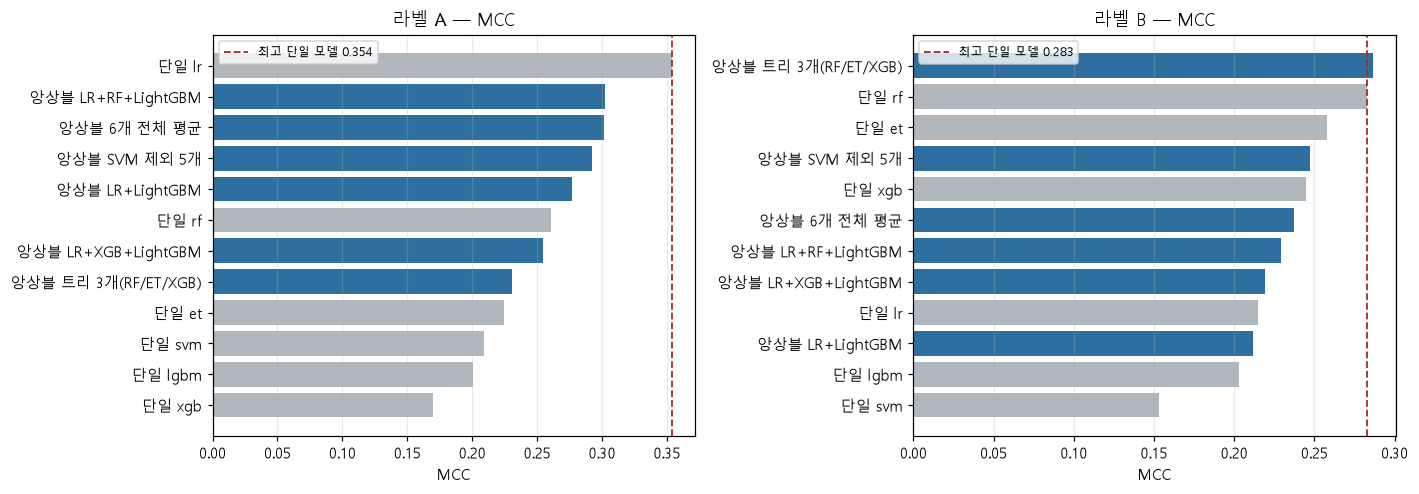

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, lab in zip(axes, ("A", "B")):
    sub = ens[ens.label == lab].sort_values("MCC")
    colors = ["#2f6f9f" if s.startswith("앙상블") else "#b0b7bd" for s in sub["구성"]]
    ax.barh(sub["구성"], sub["MCC"], color=colors)
    best_single = sub[sub["구성"].str.startswith("단일")]["MCC"].max()
    ax.axvline(best_single, color="#9c3030", ls="--", lw=1.2,
               label=f"최고 단일 모델 {best_single:.3f}")
    ax.set(title=f"라벨 {lab} — MCC", xlabel="MCC")
    ax.legend(fontsize=8)
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

---
## 03. 분할 그룹화 수정 — 요청하신 실험

완전히 같은 특징 벡터를 같은 그룹으로 묶고 다시 돌렸을 때 수치가 얼마나 내려가는지 봅니다.

- **기존 그룹화**: `comp_group_id` 와 `split_group_id` 의 연결요소 (발표된 실행과 동일)
- **완전일치벡터 병합 (2판)**: 위에 더해 2,265차원 특징 벡터를 소수 6자리로 반올림한 값이 같은 행까지 연결

03은 증강 67행을 포함한 673행 CV입니다. 606행 평가·증강 train-only production
검증과 구별해야 합니다. 아래 저장 출력은 재실행 전까지 1판 수치이며,
2판 판정은 `results/03_grouping_fix_verdict.json`과 판별표를 기준으로 확인합니다.

두 그룹화 모두 **같은 seed 3개**로 돌려서, 그룹화 때문에 생긴 차이와
분할 난수 때문에 생긴 차이를 분리합니다.

In [7]:
g = frame("03_grouping_fix")
summary = (g.groupby(["grouping", "label", "model"])[["MCC", "ROC-AUC", "sensitivity", "specificity"]]
             .mean().round(3).reset_index())
pivot = summary.pivot_table(index=["label", "model"], columns="grouping",
                            values=["MCC", "ROC-AUC"])
display(pivot.round(3))

MCC           ROC-AUC          
grouping    기존 그룹화 완전일치벡터 병합  기존 그룹화 완전일치벡터 병합
label model                                   
A     et     0.263     0.269   0.693     0.699
      lgbm   0.244     0.221   0.694     0.668
      lr     0.341     0.329   0.738     0.731
      rf     0.268     0.263   0.711     0.711
      svm    0.128     0.196   0.623     0.663
      xgb    0.253     0.225   0.694     0.675
B     et     0.232     0.250   0.627     0.638
      lgbm   0.187     0.151   0.629     0.619
      lr     0.169     0.146   0.586     0.578
      rf     0.243     0.242   0.644     0.644
      svm    0.106     0.044   0.558     0.529
      xgb    0.210     0.217   0.625     0.646

In [8]:
# seed 단위로 짝지은 차이 (병합 - 기존)
wide = g.pivot_table(index=["label", "model", "seed"], columns="grouping",
                     values=["MCC", "ROC-AUC", "sensitivity", "specificity"])
delta = pd.DataFrame({
    m: wide[(m, "완전일치벡터 병합")] - wide[(m, "기존 그룹화")]
    for m in ("MCC", "ROC-AUC", "sensitivity", "specificity")
}).reset_index()

per_model = (delta.groupby(["label", "model"])[["MCC", "ROC-AUC"]]
             .agg(["mean", "std"]).round(3))
display(per_model)

print("\n라벨별 요약 (seed 3개 × 모델 6개 = 18개 칸)")
for lab in ("A", "B"):
    sub = delta[delta.label == lab]
    print(f"  {lab}: ΔMCC 평균 {sub.MCC.mean():+.3f} (하락 {int((sub.MCC<0).sum())}/18) | "
          f"ΔAUC 평균 {sub['ROC-AUC'].mean():+.3f} (하락 {int((sub['ROC-AUC']<0).sum())}/18)")

MCC        ROC-AUC       
              mean    std    mean    std
label model                             
A     et     0.006  0.010   0.006  0.020
      lgbm  -0.023  0.045  -0.026  0.045
      lr    -0.013  0.016  -0.007  0.013
      rf    -0.005  0.029  -0.000  0.002
      svm    0.068  0.068   0.040  0.062
      xgb   -0.028  0.038  -0.019  0.030
B     et     0.019  0.042   0.011  0.046
      lgbm  -0.036  0.054  -0.010  0.046
      lr    -0.022  0.054  -0.008  0.053
      rf    -0.001  0.050   0.000  0.014
      svm   -0.062  0.037  -0.029  0.009
      xgb    0.007  0.006   0.021  0.034


라벨별 요약 (seed 3개 × 모델 6개 = 18개 칸)
  A: ΔMCC 평균 +0.001 (하락 10/18) | ΔAUC 평균 -0.001 (하락 10/18)
  B: ΔMCC 평균 -0.016 (하락 11/18) | ΔAUC 평균 -0.002 (하락 10/18)


C:\Users\DS\AppData\Local\Temp\ipykernel_15132\353865137.py:15: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\DS\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


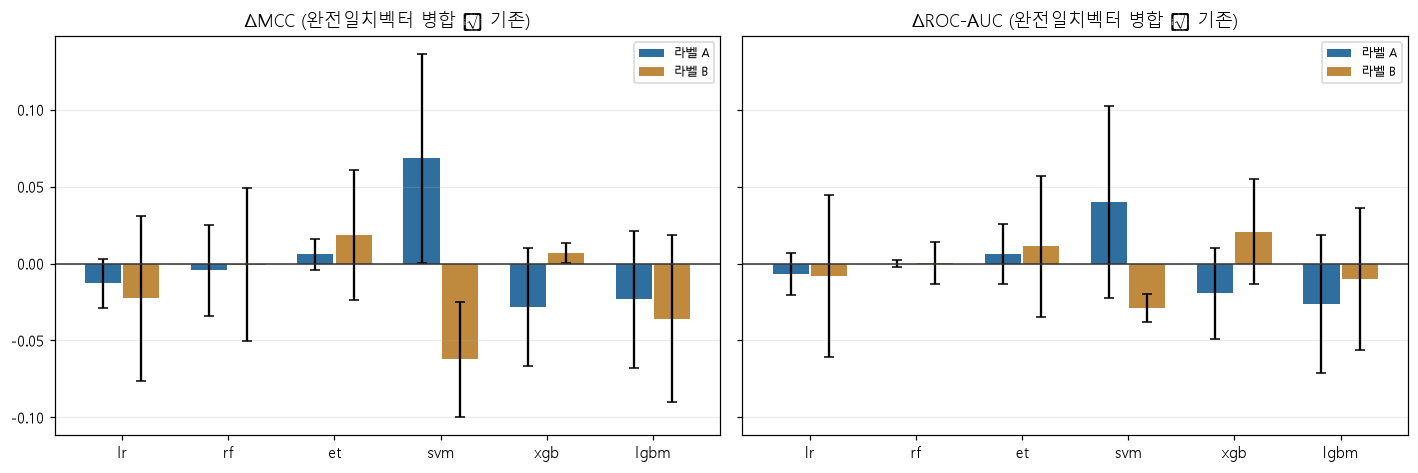

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, metric in zip(axes, ("MCC", "ROC-AUC")):
    for i, lab in enumerate(("A", "B")):
        sub = delta[delta.label == lab].groupby("model")[metric].agg(["mean", "std"])
        sub = sub.reindex(X.MODELS)
        pos = np.arange(len(sub)) + (i - 0.5) * 0.36
        ax.bar(pos, sub["mean"], 0.34, yerr=sub["std"], capsize=3,
               label=f"라벨 {lab}", color=["#2f6f9f", "#c08a3e"][i])
    ax.axhline(0, color="#333", lw=1)
    ax.set_xticks(np.arange(len(X.MODELS)))
    ax.set_xticklabels(X.MODELS)
    ax.set_title(f"Δ{metric} (완전일치벡터 병합 − 기존)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()

### 읽는 법

막대가 0보다 아래면 **그룹화를 고쳤을 때 성능이 내려갔다**는 뜻이고, 그 내려간 폭이
기존 분할이 과대평가하고 있던 양입니다. 오차 막대는 seed 3개의 표준편차이므로,
막대 길이가 오차 막대보다 짧으면 분할 난수와 구분되지 않는 수준입니다.

---
## 04. 4-class 순서형 라벨

EPA 등급은 1·2·3·4 순서형인데 지금은 A(≤2) 또는 B(≤3)로 이진화하면서 정보를 버립니다.
등급 4개를 그대로 다중분류로 학습한 뒤, 누적확률 P(≤2)와 P(≤3)로 A·B 점수를 유도합니다.
한 번의 적합으로 두 라벨을 모두 얻습니다.

비교 대상은 03의 **완전일치벡터 병합 그룹화 · 같은 seed**로 돌린 이진 모델입니다.

04~06은 기존 1판 결과입니다. 03의 6자리 반올림 2판과 섞지 않도록
04·05의 기준 arm은 `03_grouping_fix_v1.json`에 고정합니다.
기존 저장 출력과 606행 train-only production 평가는 구분해야 합니다.

In [10]:
ordn = frame("04_ordinal")
g_v1 = frame("03_grouping_fix_v1")
binary = g_v1[g_v1.grouping == "완전일치벡터 병합"].copy()
binary["approach"] = "이진 (A 또는 B)"
both = pd.concat([
    binary[["approach", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
    ordn[["approach", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
], ignore_index=True)
both = both[both.model.isin(X.MULTICLASS_MODELS)]

display(both.groupby(["label", "model", "approach"])[["MCC", "ROC-AUC"]]
        .mean().round(3).unstack("approach"))

w = both.pivot_table(index=["label", "model", "seed"], columns="approach",
                     values=["MCC", "ROC-AUC"])
d4 = pd.DataFrame({
    m: w[(m, "4-class 순서형")] - w[(m, "이진 (A 또는 B)")] for m in ("MCC", "ROC-AUC")
}).reset_index()
print("\n순서형 − 이진, 짝지은 차이")
for lab in ("A", "B"):
    s = d4[d4.label == lab]
    print(f"  {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)}) | "
          f"ΔAUC {s['ROC-AUC'].mean():+.3f} (개선 {int((s['ROC-AUC']>0).sum())}/{len(s)})")

MCC                 ROC-AUC            
approach    4-class 순서형 이진 (A 또는 B) 4-class 순서형 이진 (A 또는 B)
label model                                                
A     et          0.280       0.269       0.705       0.699
      lgbm        0.229       0.221       0.693       0.668
      lr          0.328       0.329       0.728       0.731
      rf          0.275       0.263       0.720       0.711
      xgb         0.251       0.225       0.669       0.675
B     et          0.218       0.250       0.632       0.638
      lgbm        0.189       0.151       0.633       0.619
      lr          0.234       0.146       0.627       0.578
      rf          0.194       0.242       0.631       0.644
      xgb         0.197       0.217       0.627       0.646


순서형 − 이진, 짝지은 차이
  A: ΔMCC +0.011 (개선 14/15) | ΔAUC +0.006 (개선 8/15)
  B: ΔMCC +0.005 (개선 7/15) | ΔAUC +0.005 (개선 6/15)


---
## 05. 최악 성분(worst-actor) 표현

production 특징은 성분 fingerprint를 **농도로 가중 평균**합니다.
그런데 자극성은 보통 **가장 공격적인 성분 하나**가 좌우하므로, 평균은 그 신호를 희석시킵니다.

- fingerprint: 성분별 max pooling (어느 성분에든 있으면 1)
- descriptor: 가중치가 가장 큰 성분의 값

성분 출처가 있는 행만 바뀌고 나머지는 그대로 둡니다.
두 표현의 분할은 **동일하게 고정**해서 표현 효과만 분리합니다.

In [11]:
cov = json.loads((X.RESULTS / "05_worst_actor_coverage.json").read_text(encoding="utf-8"))
print("성분 출처가 있어 재인코딩된 행 :", cov["rows_with_component_provenance"])
print("그중 실제 다성분 행           :", cov["multi_component_rows_changed"])
print("그대로 둔 행                  :", cov["rows_unchanged"])

# 기존 05와 같은 분할인 03 1판을 사용한다.
wa = frame("05_worst_actor")
g_v1 = frame("03_grouping_fix_v1")
base_arm = g_v1[(g_v1.grouping == "완전일치벡터 병합") & (g_v1.seed.isin(sorted(wa.seed.unique())))].copy()
base_arm["표현"] = "기준 농도가중"
wa = pd.concat([
    wa[["표현", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
    base_arm[["표현", "label", "seed", "model", "MCC", "ROC-AUC", "sensitivity", "specificity"]],
], ignore_index=True)
display(wa.groupby(["label", "model", "표현"])[["MCC", "ROC-AUC"]].mean().round(3).unstack("표현"))

w5 = wa.pivot_table(index=["label", "model", "seed"], columns="표현",
                    values=["MCC", "ROC-AUC"])
d5 = pd.DataFrame({
    m: w5[(m, "최악 성분 pooling")] - w5[(m, "기준 농도가중")] for m in ("MCC", "ROC-AUC")
}).reset_index()
print("\n최악 성분 − 기준, 짝지은 차이")
for lab in ("A", "B"):
    s = d5[d5.label == lab]
    print(f"  {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)}) | "
          f"ΔAUC {s['ROC-AUC'].mean():+.3f} (개선 {int((s['ROC-AUC']>0).sum())}/{len(s)})")

성분 출처가 있어 재인코딩된 행 : 606
그중 실제 다성분 행           : 228
그대로 둔 행                  : 67


MCC               ROC-AUC              
표현          기준 농도가중 최악 성분 pooling 기준 농도가중 최악 성분 pooling
label model                                            
A     et      0.260         0.272   0.691         0.703
      lgbm    0.227         0.189   0.673         0.645
      lr      0.329         0.309   0.730         0.730
      rf      0.267         0.240   0.713         0.686
      svm     0.196         0.183   0.673         0.614
      xgb     0.226         0.226   0.676         0.683
B     et      0.252         0.228   0.643         0.628
      lgbm    0.141         0.209   0.619         0.643
      lr      0.140         0.148   0.568         0.602
      rf      0.237         0.212   0.648         0.637
      svm     0.060         0.128   0.535         0.570
      xgb     0.225         0.204   0.647         0.642


최악 성분 − 기준, 짝지은 차이
  A: ΔMCC -0.014 (개선 4/12) | ΔAUC -0.016 (개선 5/12)
  B: ΔMCC +0.012 (개선 6/12) | ΔAUC +0.010 (개선 8/12)


---
## 06. 특징 집합 재조합

특성이 2,265개인데 표본이 673개입니다(p ≫ n). 발표된 결과에서 **LR이 트리 계열을 전부 이긴 것**은
정규화가 핵심이고 트리가 희소 이진 특징에서 과적합한다는 신호입니다. 특징을 줄이면 어떻게 되는지 봅니다.

새 descriptor를 계산하지는 않고, **기존 2,265개를 재조합**만 합니다.

In [12]:
rep = frame("06_representations")
tab = (rep.groupby(["label", "특징집합", "n_features", "model"])[["MCC", "ROC-AUC"]]
       .mean().round(3).reset_index())
for lab in ("A", "B"):
    print(f"\n── 라벨 {lab} ──")
    print(tab[tab.label == lab].pivot_table(
        index=["특징집합", "n_features"], columns="model", values="MCC"
    ).round(3).to_string())


── 라벨 A ──
model                          lgbm     lr    xgb
특징집합              n_features                     
descriptor만 217   217         0.205  0.255  0.240
fingerprint만 2048 2048        0.263  0.321  0.256
fp1024 접기+desc    1241        0.233  0.328  0.231
기준 fp2048+desc217 2265        0.227  0.329  0.226
물성 22+fp1024      1046        0.290  0.335  0.270
물성 소수집합 22        22          0.205  0.204  0.210

── 라벨 B ──
model                          lgbm     lr    xgb
특징집합              n_features                     
descriptor만 217   217         0.199  0.170  0.232
fingerprint만 2048 2048        0.198  0.148  0.149
fp1024 접기+desc    1241        0.192  0.167  0.209
기준 fp2048+desc217 2265        0.141  0.140  0.225
물성 22+fp1024      1046        0.149  0.153  0.156
물성 소수집합 22        22          0.138  0.172  0.094


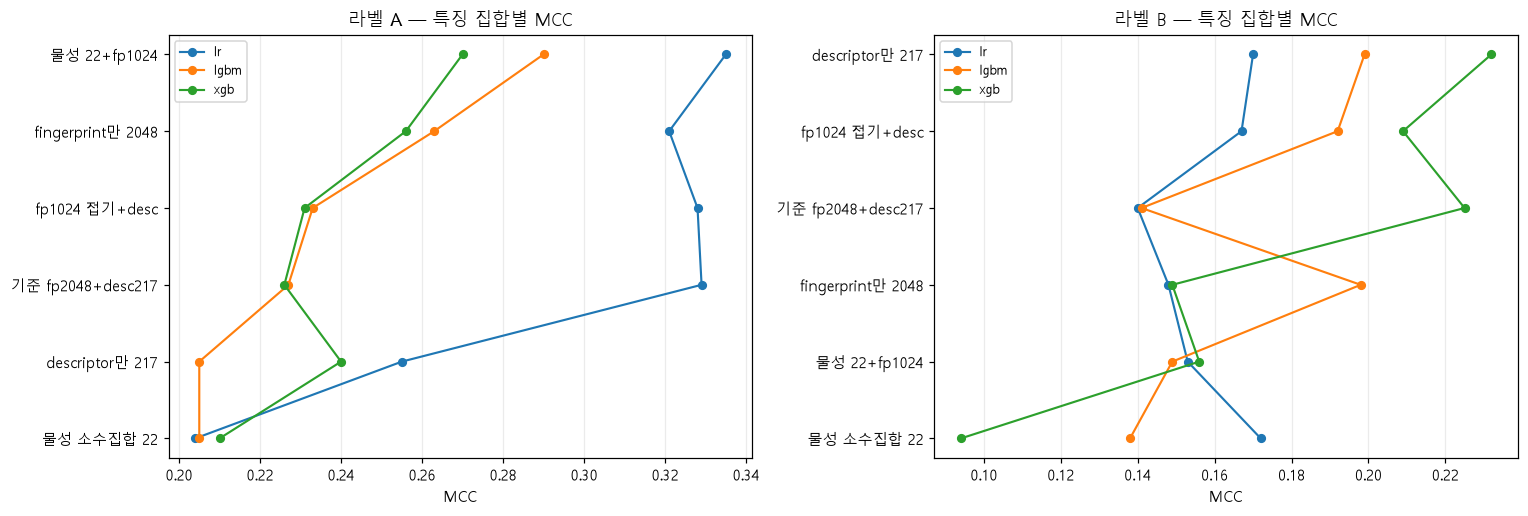

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
for ax, lab in zip(axes, ("A", "B")):
    sub = tab[tab.label == lab]
    order = (sub.groupby("특징집합")["MCC"].mean().sort_values().index)
    for model in ["lr", "lgbm", "xgb"]:
        s = sub[sub.model == model].set_index("특징집합").reindex(order)
        ax.plot(s["MCC"], s.index, "o-", label=model, lw=1.4, ms=5)
    ax.set(title=f"라벨 {lab} — 특징 집합별 MCC", xlabel="MCC")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()

---
## 종합

In [14]:
lines = []

d = delta.groupby("label")[["MCC", "ROC-AUC"]].mean()
lines.append("【03 분할 그룹화 수정】")
for lab in ("A", "B"):
    n_down = int((delta[delta.label == lab].MCC < 0).sum())
    lines.append(f"  라벨 {lab}: ΔMCC {d.loc[lab,'MCC']:+.3f}, ΔAUC {d.loc[lab,'ROC-AUC']:+.3f} "
                 f"(18칸 중 {n_down}칸 하락)")

lines.append("\n【01 상한】")
for row in ceil.to_dict("records"):
    lines.append(f"  라벨 {row['label']}: 중복 노이즈 상한 MCC {row['ceiling_MCC']:.3f} "
                 f"— 현재 최고와의 여유가 큼")

lines.append("\n【02 앙상블】")
for lab in ("A", "B"):
    sub = ens[ens.label == lab]
    best_e = sub[sub["구성"].str.startswith("앙상블")].sort_values("MCC").iloc[-1]
    best_s = sub[sub["구성"].str.startswith("단일")].sort_values("MCC").iloc[-1]
    lines.append(f"  라벨 {lab}: 최고 앙상블 {best_e['구성']} MCC {best_e.MCC:.3f} "
                 f"vs 최고 단일 {best_s['구성']} MCC {best_s.MCC:.3f} "
                 f"({best_e.MCC - best_s.MCC:+.3f})")

lines.append("\n【04 순서형】")
for lab in ("A", "B"):
    s = d4[d4.label == lab]
    lines.append(f"  라벨 {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)})")

lines.append("\n【05 최악 성분 표현】")
for lab in ("A", "B"):
    s = d5[d5.label == lab]
    lines.append(f"  라벨 {lab}: ΔMCC {s.MCC.mean():+.3f} (개선 {int((s.MCC>0).sum())}/{len(s)})")

lines.append("\n【06 특징 집합】 라벨별 최고 조합")
for lab in ("A", "B"):
    s = tab[tab.label == lab].sort_values("MCC").iloc[-1]
    base = tab[(tab.label == lab) & (tab["특징집합"] == "기준 fp2048+desc217")
               & (tab.model == s.model)]["MCC"].iloc[0]
    lines.append(f"  라벨 {lab}: {s['특징집합']} ({s.n_features}개) + {s.model} "
                 f"MCC {s.MCC:.3f} (같은 모델 기준 대비 {s.MCC - base:+.3f})")

print("\n".join(lines))

【03 분할 그룹화 수정】
  라벨 A: ΔMCC +0.001, ΔAUC -0.001 (18칸 중 10칸 하락)
  라벨 B: ΔMCC -0.016, ΔAUC -0.002 (18칸 중 11칸 하락)

【01 상한】
  라벨 A: 중복 노이즈 상한 MCC 0.861 — 현재 최고와의 여유가 큼
  라벨 B: 중복 노이즈 상한 MCC 0.795 — 현재 최고와의 여유가 큼

【02 앙상블】
  라벨 A: 최고 앙상블 앙상블 LR+RF+LightGBM MCC 0.302 vs 최고 단일 단일 lr MCC 0.354 (-0.052)
  라벨 B: 최고 앙상블 앙상블 트리 3개(RF/ET/XGB) MCC 0.287 vs 최고 단일 단일 rf MCC 0.283 (+0.004)

【04 순서형】
  라벨 A: ΔMCC +0.011 (개선 14/15)
  라벨 B: ΔMCC +0.005 (개선 7/15)

【05 최악 성분 표현】
  라벨 A: ΔMCC -0.014 (개선 4/12)
  라벨 B: ΔMCC +0.012 (개선 6/12)

【06 특징 집합】 라벨별 최고 조합
  라벨 A: 물성 22+fp1024 (1046개) + lr MCC 0.335 (같은 모델 기준 대비 +0.006)
  라벨 B: descriptor만 217 (217개) + xgb MCC 0.232 (같은 모델 기준 대비 +0.007)


### 해석의 한계

- 후보 격자를 20개 중 6개로 줄였습니다. **절대 수치는 발표된 production 결과와 다를 수 있고**,
  여기서 유효한 것은 같은 조건에서 짝지어 비교한 차이뿐입니다.
- seed 2~3개의 표준편차는 신뢰구간이 아닙니다. 통계적 유의성을 선언하지 않습니다.
- 05는 성분 출처가 있는 606행에만 영향을 주며, 실제 다성분 행은 그보다 적습니다.
- 모두 내부 교차검증 결과입니다. 외부 독립 데이터 검증이나 배포 성능 보장이 아닙니다.
- 중복 673→444행 문제는 03이 분할만 고쳤을 뿐, 행을 합치거나 가중치를 낮추지는 않았습니다.